# Práctica 2 — Filtrado colaborativo con SVD truncada

**Objetivo:** el mismo que en `filtrado_colaborativo_knn.ipynb`: predecir las 40.000 valoraciones ocultas (con un `99`)
en `recommendation_dataset.csv`, midiendo la calidad con el **MAE** (error absoluto medio). Cambia el **método**:

- **k-NN** (el otro notebook) predice la nota de un restaurante a partir de los restaurantes **más parecidos** que el
  usuario ya ha valorado.
- **SVD truncada** (este notebook) resume los gustos de todos los usuarios en unos pocos **"ejes de gusto"** y predice
  a partir de dónde está cada usuario y cada restaurante en esos ejes.

**Cómo está organizado el notebook** (mismo procedimiento que el de k-NN):

1. **Carga de datos.**
2. **Validación propia**: las mismas 40.000 valoraciones apartadas que en k-NN (misma función, misma semilla).
3. **Sesgos de usuario y de restaurante**: la base sobre la que trabaja la SVD.
4. **SVD truncada sobre los residuos** (el método de este notebook).
5. **Resumen** y guardado de las predicciones de validación (para `comparativa.ipynb`).
6. **Predicción final** con todos los datos → `predicciones/resultats_svd.csv`.
7. **Comprobación oficial** con el script `compute_mae.py` del enunciado.

Las secciones 1–3 son **las mismas que en el notebook de k-NN**: copiamos sus funciones tal cual para que este
notebook se pueda ejecutar solo. La entrega (`resultats.csv`) la genera el notebook de k-NN; este escribe sus
predicciones en la carpeta `predicciones/` para no sobrescribirla.

Las celdas que empiezan por `# Comprobaciones` contienen `assert`: si algo no es como esperamos, el notebook se
detiene ahí.

In [1]:
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Carpeta con los ficheros del enunciado (ruta relativa: el notebook se ejecuta desde la carpeta P2_SIO)
RUTA_DATOS = "ConjuntDades_P2"
SEMILLA = 42          # la misma semilla que en el notebook de k-NN: así se apartan las mismas valoraciones
N_VALIDACION = 40000  # cuántas valoraciones conocidas apartamos para validar (las mismas que tiene el test)

## 1. Carga de datos

Igual que en el notebook de k-NN: leemos `recommendation_dataset.csv` (usuarios en filas, restaurantes en columnas,
separado por `;`) en una matriz `R` de tipo **`float32`**, y convertimos los `99` (nota desconocida) en **`NaN`**.
De `template.csv` sacamos las posiciones (fila, columna) de las 40.000 celdas que hay que predecir.

In [2]:
def cargar_matriz(ruta):
    """Lee el CSV de valoraciones y devuelve (R, usuarios, restaurantes).

    R: matriz float32 (n_usuarios, n_restaurantes) con NaN donde la valoración es desconocida.
    usuarios / restaurantes: nombres de filas ("User1", ...) y columnas ("Restaurant1", ...).
    """
    df = pd.read_csv(ruta, sep=";", index_col=0)   # la primera columna (User1, User2, ...) es el índice
    R = df.to_numpy(dtype=np.float32)
    R[R == 99] = np.nan                            # 99 = desconocido  ->  NaN
    return R, df.index.to_numpy(), df.columns.to_numpy()


def cargar_posiciones(ruta, usuarios, restaurantes):
    """Lee template.csv y traduce cada par (usuario, restaurante) a su (fila, columna) dentro de R.

    Devuelve (plantilla, filas_u, cols_i): la tabla original (para escribir luego el resultado en el
    mismo orden) y dos arrays de enteros con las posiciones a predecir.
    """
    # Cada línea es "User25287;Restaurant31;" -> la tercera columna viene vacía y la descartamos
    plantilla = pd.read_csv(ruta, sep=";", header=None, names=["usuario", "restaurante", "vacia"])
    plantilla = plantilla.drop(columns="vacia")
    # Diccionarios nombre -> posición, p. ej. "User1" -> 0, "Restaurant31" -> 30
    fila_de = {nombre: k for k, nombre in enumerate(usuarios)}
    col_de = {nombre: k for k, nombre in enumerate(restaurantes)}
    filas_u = plantilla["usuario"].map(fila_de).to_numpy()
    cols_i = plantilla["restaurante"].map(col_de).to_numpy()
    return plantilla, filas_u, cols_i

In [3]:
R, usuarios, restaurantes = cargar_matriz(f"{RUTA_DATOS}/recommendation_dataset.csv")
plantilla, filas_u, cols_i = cargar_posiciones(f"{RUTA_DATOS}/template.csv", usuarios, restaurantes)
print(f"Matriz R: {R.shape[0]:,} usuarios x {R.shape[1]} restaurantes")
print(f"Posiciones a predecir: {len(plantilla):,}")

Matriz R: 73,421 usuarios x 100 restaurantes
Posiciones a predecir: 40,000


In [4]:
# Comprobaciones de la carga
assert R.shape == (73421, 100) and R.dtype == np.float32
assert abs(np.isfinite(R).mean() - 0.558) < 0.001          # densidad del enunciado
assert np.nanmin(R) >= -10 and np.nanmax(R) <= 10           # no queda ningún 99
assert len(plantilla) == 40000 and len(filas_u) == len(cols_i) == 40000
assert np.isnan(R[filas_u, cols_i]).all()                   # las celdas a predecir son desconocidas
print("Carga correcta")

Carga correcta


## 2. Validación propia

Para elegir los parámetros de la SVD necesitamos medir el MAE **sin mirar el test oficial** (sería como preparar un
examen mirando las respuestas). Igual que en k-NN, apartamos al azar 40.000 valoraciones **conocidas**, las ocultamos
en una copia de la matriz (`R_train`), entrenamos solo con `R_train` y comparamos nuestras predicciones con los
valores reales apartados (`val_real`):

$$\text{MAE} = \frac{1}{n}\sum_{k=1}^{n} |\text{real}_k - \text{predicción}_k|$$

Como usamos **la misma función y la misma semilla (42)** que en el notebook de k-NN, se apartan exactamente las
mismas 40.000 valoraciones: los dos métodos hacen el mismo "examen de práctica" y sus MAE se pueden comparar.
El test oficial solo se usa una vez, al final (sección 7).

In [5]:
def crear_validacion(R, n=N_VALIDACION, semilla=SEMILLA):
    """Aparta n valoraciones conocidas, elegidas al azar, para usarlas como "examen de práctica".

    Devuelve (R_train, val_u, val_i, val_real):
      R_train   copia de R con esas n celdas puestas a NaN (con ella aprenderán los métodos)
      val_u     filas (usuarios) de las celdas apartadas
      val_i     columnas (restaurantes) de las celdas apartadas
      val_real  sus valores reales, para compararlos con nuestras predicciones
    """
    generador = np.random.default_rng(semilla)
    filas, cols = np.nonzero(np.isfinite(R))                   # posiciones de todas las notas conocidas
    elegidas = generador.choice(len(filas), size=n, replace=False)
    val_u, val_i = filas[elegidas], cols[elegidas]
    val_real = R[val_u, val_i].copy()
    R_train = R.copy()                                         # copia: la R original no se modifica
    R_train[val_u, val_i] = np.nan
    return R_train, val_u, val_i, val_real


def mae(pred, real):
    """Error absoluto medio: media de |predicción - valor real|."""
    return float(np.mean(np.abs(pred - real)))

In [6]:
R_train, val_u, val_i, val_real = crear_validacion(R)
resultados = {}   # aquí guardaremos el MAE de validación de cada método: {"nombre del método": MAE}
print(f"Valoraciones para entrenar: {np.isfinite(R_train).sum():,}   |   para validar: {len(val_real):,}")

Valoraciones para entrenar: 4,056,360   |   para validar: 40,000


In [7]:
# Comprobaciones de la validación
assert mae(np.array([1., -2.]), np.array([0., 0.])) == 1.5   # (|1-0| + |-2-0|) / 2
assert np.isnan(R_train[val_u, val_i]).all()                 # ocultas en entrenamiento
assert np.isfinite(R[val_u, val_i]).all()                    # R original intacta
assert np.isfinite(R_train).sum() == np.isfinite(R).sum() - N_VALIDACION
# Misma semilla -> mismas celdas. (Esta llamada crea una copia temporal de R que se libera al acabar la comprobación.)
assert np.array_equal(crear_validacion(R)[1], val_u)
print("Validación correcta")

Validación correcta


## 3. Sesgos de usuario y de restaurante (la base)

Antes de buscar "gustos", quitamos lo más evidente: hay usuarios que puntúan alto todo y restaurantes que gustan a
casi todos. Lo modelamos igual que en el notebook de k-NN:

$$\hat r_{ui} = \mu + b_u + b_i$$

- $\mu$: media global de todas las notas.
- $b_u$: **sesgo del usuario** $u$ (cuánto puntúa por encima o por debajo de la media).
- $b_i$: **sesgo del restaurante** $i$ (cuánto mejor o peor valorado está, una vez descontado quién lo ha puntuado).

Los sesgos se calculan **alternando** unas cuantas veces (10), con una regularización λ que desconfía de quien tiene
pocas notas:

$$b_i = \frac{\sum_{u \in U_i} (r_{ui} - \mu - b_u)}{|U_i| + \lambda_i} \qquad\qquad b_u = \frac{\sum_{i \in I_u} (r_{ui} - \mu - b_i)}{|I_u| + \lambda_u}$$

donde $U_i$ son los usuarios que han valorado el restaurante $i$, e $I_u$ los restaurantes que ha valorado el usuario $u$.

En este notebook los sesgos son la **base**: la SVD (sección 4) intentará explicar lo que los sesgos no explican.

In [8]:
def calcular_sesgos(R, lam_u, lam_i, n_iter=10):
    """Calcula la media global mu y los sesgos regularizados de usuarios (b_u) y restaurantes (b_i).

    Modelo: nota(u, i) ≈ mu + b_u[u] + b_i[i]. Se alterna n_iter veces: primero se recalcula b_i
    con b_u fijo y después b_u con b_i fijo. lam_u / lam_i son las regularizaciones λ.
    """
    conocida = np.isfinite(R)                                   # máscara: True donde hay nota
    mu = float(np.nanmean(R))
    D = np.where(conocida, R - mu, 0).astype(np.float32)        # r_ui - mu (0 en los huecos, así no suman)
    n_u = conocida.sum(axis=1)                                  # nº de notas de cada usuario   |I_u|
    n_i = conocida.sum(axis=0)                                  # nº de notas de cada restaurante |U_i|
    b_u = np.zeros(R.shape[0], np.float32)
    b_i = np.zeros(R.shape[1], np.float32)

    for _ in range(n_iter):
        # b_i: suma de (r_ui - mu - b_u) de los usuarios que valoraron i, dividida por |U_i| + λ_i
        suma_i = (D - b_u[:, None] * conocida).sum(axis=0)
        b_i = np.divide(suma_i, n_i + lam_i, out=np.zeros_like(b_i), where=(n_i + lam_i) > 0)
        # b_u: suma de (r_ui - mu - b_i) de los restaurantes que valoró u, dividida por |I_u| + λ_u
        suma_u = (D - b_i[None, :] * conocida).sum(axis=1)
        b_u = np.divide(suma_u, n_u + lam_u, out=np.zeros_like(b_u), where=(n_u + lam_u) > 0)
        # (where=... evita dividir por 0: quien no tiene ninguna nota se queda con sesgo 0)

    return mu, b_u, b_i

In [9]:
# Comprobaciones de calcular_sesgos con un ejemplo pequeño que podemos razonar a mano:
# construimos notas que son EXACTAMENTE "1 + sesgo del usuario + sesgo del restaurante".
a = np.array([0, 1, -1, 2], np.float32)       # sesgos de 4 usuarios
c = np.array([0.5, -0.5, 0], np.float32)      # sesgos de 3 restaurantes
R_ej = (1 + a[:, None] + c[None, :]).astype(np.float32)
mu_ej, bu_ej, bi_ej = calcular_sesgos(R_ej, 0, 0, n_iter=20)
assert np.allclose(mu_ej + bu_ej[:, None] + bi_ej[None, :], R_ej, atol=1e-4)   # debe reconstruir las notas

R_ej2 = np.vstack([R_ej, np.full((1, 3), np.nan, np.float32)])  # añadimos un usuario sin ninguna valoración
assert np.isfinite(calcular_sesgos(R_ej2, 0, 0)[1]).all()       # su sesgo debe ser 0, no NaN
print("calcular_sesgos correcta")

calcular_sesgos correcta


**Elección de λ.** Probamos las mismas combinaciones de $\lambda_u$ y $\lambda_i$ que en el notebook de k-NN y nos
quedamos con la de menor MAE en la validación (filas: $\lambda_u$, columnas: $\lambda_i$).

In [10]:
lams_u = [0, 2, 5, 10, 20]
lams_i = [0, 25, 100]
tabla_sesgos = pd.DataFrame(index=lams_u, columns=lams_i, dtype=float)
tabla_sesgos.index.name, tabla_sesgos.columns.name = "λ usuario", "λ restaurante"

for lam_u in lams_u:
    for lam_i in lams_i:
        mu, b_u, b_i = calcular_sesgos(R_train, lam_u, lam_i)
        pred = np.clip(mu + b_u[val_u] + b_i[val_i], -10, 10)
        tabla_sesgos.loc[lam_u, lam_i] = mae(pred, val_real)

display(tabla_sesgos.round(4))

mejor_lam_u, mejor_lam_i = tabla_sesgos.stack().idxmin()      # posición (fila, columna) del MAE mínimo
resultados["Sesgos"] = float(tabla_sesgos.loc[mejor_lam_u, mejor_lam_i])
print(f"Mejor combinación: λ_u = {mejor_lam_u}, λ_i = {mejor_lam_i}  ->  MAE validación = {resultados['Sesgos']:.3f}")

λ restaurante,0,25,100
λ usuario,,,
0,3.4689,3.4689,3.4690
2,3.4767,3.4767,3.4768
5,3.4908,3.4908,3.4909
10,3.5164,3.5165,3.5166
20,3.5669,3.5670,3.5671


Mejor combinación: λ_u = 0, λ_i = 0  ->  MAE validación = 3.469


**Resultado:** como en el notebook de k-NN, la mejor combinación es **λ = 0**: la regularización no ayuda, porque cada
usuario y cada restaurante tienen suficientes notas para que sus sesgos sean fiables sin "encogerlos".

In [11]:
# Comprobaciones de los sesgos
assert resultados["Sesgos"] < 3.55
assert mejor_lam_u == 0 and mejor_lam_i == 0      # lo que dice el texto de arriba
print("Sesgos correctos")

Sesgos correctos


## 4. SVD truncada sobre los residuos

### La idea: trabajar con los residuos

Después de los sesgos queda el **residuo** de cada nota conocida, lo que los sesgos no explican:

$$e_{ui} = r_{ui} - (\mu + b_u + b_i)$$

El residuo recoge los **gustos** concretos de cada usuario (por ejemplo, "puntúa bajo en general, pero este tipo de
restaurante le encanta"). Igual que en k-NN, trabajamos sobre residuos para comparar gustos y no generosidad.

Guardamos los residuos en una matriz `E` (usuarios × restaurantes). En las celdas **sin nota ponemos 0**: no sabemos
nada de esa celda, así que no le añadimos nada a lo que ya dicen los sesgos.

### Qué es la SVD

La **descomposición en valores singulares** (SVD) escribe cualquier matriz como un producto de tres:

$$E = U \, \Sigma \, V^T$$

- Las columnas de $V$ (100 × 100) son **ejes de gusto**: cada eje es una combinación de restaurantes que tienden a
  gustar (o disgustar) juntos. No los elegimos nosotros: salen de los datos.
- $\Sigma$ es diagonal y contiene los **valores singulares** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$: cuánto pesa
  cada eje en los datos. Los ejes vienen ordenados de más a menos importante.
- $U\Sigma$ dice dónde está cada usuario en cada eje.

### Por qué "truncada"

Si nos quedamos solo con los $f$ primeros ejes, obtenemos la **mejor aproximación posible de $E$ con $f$ ejes**. Los
primeros recogen los gustos que comparten muchos usuarios; los últimos, sobre todo ruido y los ceros de los huecos.
Por eso, con pocos ejes la reconstrucción **rellena los huecos** con lo que predicen los gustos comunes. En cambio,
con los 100 ejes se reconstruye $E$ exactamente, ceros incluidos, y en los huecos no se aprende nada.

### La predicción

Las columnas de $V$ son ortonormales (perpendiculares y de longitud 1), así que la posición del usuario $u$ en los $f$
primeros ejes se obtiene **proyectando** su fila de residuos: $p_u = e_u \, V_f$ (sus "gustos"). La predicción es:

$$\hat r_{ui} = \mu + b_u + b_i + p_u \cdot v_i = \mu + b_u + b_i + \sum_{j=1}^{f} p_{uj} \, V_{ij}$$

donde $v_i$ es la fila $i$ de $V_f$ (cómo se sitúa el restaurante $i$ en esos ejes). Como siempre, se recorta a [−10, 10].

**Sobre las librerías:** la descomposición $E = U\Sigma V^T$ la calcula `np.linalg.svd` de numpy, una operación
matemática general (como multiplicar matrices), que el enunciado permite. El método de recomendación (residuos,
huecos a 0, quedarse con $f$ ejes y predecir) es nuestro.

In [12]:
def calcular_residuos(R, mu, b_u, b_i):
    """Devuelve (E, M): E = r_ui - (mu + b_u + b_i) donde hay nota y 0 en los huecos; M = máscara de notas conocidas."""
    M = np.isfinite(R)
    E = np.where(M, R - (mu + b_u[:, None] + b_i[None, :]), 0).astype(np.float32)
    return E, M


def calcular_factores(E):
    """SVD de la matriz de residuos: E = U·Σ·Vᵀ. Devuelve (V, s).

    V: matriz (n_restaurantes x n_restaurantes); la columna j es el eje de gusto j, de más a menos importante.
    s: valores singulares σ_1 ≥ σ_2 ≥ ... (cuánto pesa cada eje).
    U no la guardamos: la posición de cada usuario se obtiene proyectando su fila de residuos (ver predecir_svd).
    """
    _, s, Vt = np.linalg.svd(E, full_matrices=False)   # full_matrices=False: U de 73.421 x 100, no de 73.421 x 73.421
    return Vt.T.astype(np.float32), s.astype(np.float32)


def predecir_svd(E, V, mu, b_u, b_i, u, i, f):
    """Predice la nota de cada par (u[n], i[n]) con los f primeros ejes de la SVD. Devuelve un array recortado a [-10, 10]."""
    base = mu + b_u[u] + b_i[i]                  # predicción de los sesgos (sección 3)
    V_f = V[:, :f]                               # nos quedamos con los f ejes más importantes
    gustos = E[u] @ V_f                          # (n, f): posición de cada usuario en esos ejes, p_u = e_u · V_f
    ajuste = (gustos * V_f[i]).sum(axis=1)       # p_u · v_i: lo que los gustos del usuario dicen del restaurante i
    return np.clip(base + ajuste, -10, 10).astype(np.float32)

In [13]:
# Comprobaciones de la SVD con ejemplos pequeños que podemos razonar a mano.
# Matriz de rango 1 (3 usuarios x 3 restaurantes): cada fila es un múltiplo de [2, 0, 1] -> un solo eje basta.
E_ej = np.outer([1, 2, -1], [2, 0, 1]).astype(np.float32)        # [[2,0,1],[4,0,2],[-2,0,-1]]
V_ej, s_ej = calcular_factores(E_ej)
cero_u, cero_i = np.zeros(3, np.float32), np.zeros(3, np.float32)
todos_u, todos_i = np.repeat(np.arange(3), 3), np.tile(np.arange(3), 3)
assert np.allclose(predecir_svd(E_ej, V_ej, 0., cero_u, cero_i, todos_u, todos_i, f=1), E_ej.ravel(), atol=1e-5)
assert np.allclose(s_ej[1:], 0, atol=1e-5)                        # el resto de ejes no aportan nada
# Con f = todos los ejes se reconstruye exactamente cualquier matriz
E_ej2 = np.array([[1, -2, 0], [3, 1, 2], [0, 0, -1], [2, 2, 2]], np.float32)
V_ej2, _ = calcular_factores(E_ej2)
u4, i4 = np.repeat(np.arange(4), 3), np.tile(np.arange(3), 4)
assert np.allclose(predecir_svd(E_ej2, V_ej2, 0., np.zeros(4, np.float32), cero_i, u4, i4, f=3), E_ej2.ravel(), atol=1e-5)
# La base μ + b_u + b_i se suma y el resultado se recorta a [-10, 10]
assert np.isclose(predecir_svd(E_ej, V_ej, 1., cero_u + 0.5, cero_i, np.array([1]), np.array([0]), f=1)[0], 1.5 + 4)
assert predecir_svd(E_ej, V_ej, 9., cero_u, cero_i, np.array([1]), np.array([0]), f=1)[0] <= 10
print("SVD correcta")

SVD correcta


### Elección del número de ejes f

Calculamos los sesgos, los residuos y la SVD **una sola vez** con `R_train` (y los mejores λ). Para cada valor de $f$
solo cambia cuántos ejes usamos al predecir, así que probar muchos valores es casi gratis.

Primero miramos **cuánto pesa cada eje**: el porcentaje acumulado de $\sigma^2$ indica qué parte de la "energía" de
$E$ recogen los $f$ primeros ejes.

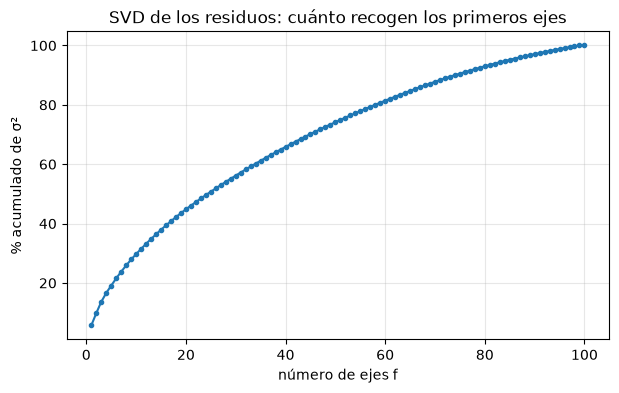

Los  1 primeros ejes recogen el   5.7 % de σ²
Los  5 primeros ejes recogen el  19.1 % de σ²
Los 10 primeros ejes recogen el  29.7 % de σ²
Los 20 primeros ejes recogen el  44.8 % de σ²
Los 50 primeros ejes recogen el  74.2 % de σ²


In [14]:
# Sesgos, residuos y SVD: UNA sola vez con R_train; para cada f solo cambia cuántos ejes usamos
mu, b_u, b_i = calcular_sesgos(R_train, mejor_lam_u, mejor_lam_i)
E, M = calcular_residuos(R_train, mu, b_u, b_i)
V, s = calcular_factores(E)

# Porcentaje acumulado de σ² según el número de ejes
energia = 100 * np.cumsum(s.astype(np.float64) ** 2) / np.sum(s.astype(np.float64) ** 2)
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(s) + 1), energia, marker=".")
plt.xlabel("número de ejes f")
plt.ylabel("% acumulado de σ²")
plt.title("SVD de los residuos: cuánto recogen los primeros ejes")
plt.grid(alpha=0.3)
plt.show()
for f in (1, 5, 10, 20, 50):
    print(f"Los {f:>2} primeros ejes recogen el {energia[f - 1]:5.1f} % de σ²")

Los ejes están ordenados, así que los primeros pesan más, pero la curva sube **de forma gradual**: con 10 ejes se
recoge menos de un tercio de $\sigma^2$. No hay un corte evidente a simple vista, así que elegimos $f$ como en k-NN
elegimos $k$: probando varios valores y midiendo el MAE en la validación.

In [15]:
valores_f = [1, 2, 3, 5, 8, 10, 12, 15, 20, 30, 50, 100]
mae_por_f = pd.Series(index=valores_f, dtype=float, name="MAE validación")
mae_por_f.index.name = "f"
for f in valores_f:
    pred = predecir_svd(E, V, mu, b_u, b_i, val_u, val_i, f)
    mae_por_f[f] = mae(pred, val_real)

mejor_f = int(mae_por_f.idxmin())
resultados["SVD"] = float(mae_por_f[mejor_f])
display(mae_por_f.round(4).to_frame())
print(f"Mejor f = {mejor_f}  ->  MAE validación = {resultados['SVD']:.3f}")

,MAE validación
f,
1,3.3755
2,3.3157
3,3.2656
5,3.2266
8,3.1916
10,3.1693
12,3.1665
15,3.1758
20,3.1908


Mejor f = 12  ->  MAE validación = 3.167


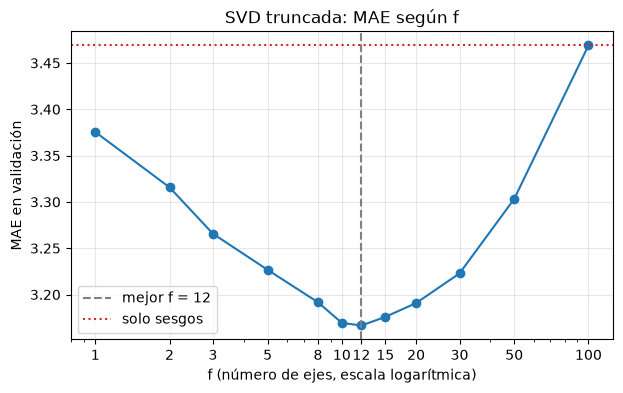

In [16]:
# Gráfica: MAE de validación según el número de ejes f
plt.figure(figsize=(7, 4))
plt.plot(mae_por_f.index, mae_por_f.values, marker="o")
plt.axvline(mejor_f, color="gray", linestyle="--", label=f"mejor f = {mejor_f}")
plt.axhline(resultados["Sesgos"], color="tab:red", linestyle=":", label="solo sesgos")
plt.xscale("log")                              # escala logarítmica en x: así se ven bien los valores pequeños de f
plt.xticks(valores_f, valores_f)
plt.xlabel("f (número de ejes, escala logarítmica)")
plt.ylabel("MAE en validación")
plt.title("SVD truncada: MAE según f")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Resultado:** el mejor valor es **f = 12**, que mejora claramente a los sesgos. La curva tiene forma de U:

- Con **pocos ejes** (f = 1, 2, 3) la SVD solo capta los gustos más generales y se queda corta.
- Con **demasiados ejes** empieza a copiar el ruido y los ceros de los huecos, y el MAE vuelve a subir.
- Con **f = 100** reconstruye $E$ exactamente: en las celdas ocultas $E$ vale 0, así que la predicción es la de los
  sesgos y da su mismo MAE. Esto, además, comprueba que las notas de validación no se han colado en el entrenamiento
  (si estuvieran en $E$, la SVD las "recordaría" y el MAE sería mucho menor).

In [17]:
# Comprobaciones de la SVD con los datos reales
assert resultados["SVD"] < resultados["Sesgos"] and resultados["SVD"] < 3.25
# Con los 100 ejes, E·V·Vᵀ = E: en las celdas ocultas E vale 0, así que la SVD no añade nada -> mismo MAE que los sesgos
# (si las celdas de validación se hubieran colado en E, aquí saldría un MAE mucho menor)
assert abs(mae_por_f[100] - resultados["Sesgos"]) < 1e-3
assert np.allclose(V.T @ V, np.eye(V.shape[1]), atol=1e-4) and np.all(np.diff(s) <= 0)   # ejes ortonormales y ordenados
assert mejor_f == 12 and energia[9] < 100 / 3                     # lo que dicen los textos de arriba
print("SVD mejora a los sesgos")

SVD mejora a los sesgos


## 5. Resumen

MAE de validación de los sesgos (la base) y de la SVD, y cuánto mejora la SVD a los sesgos. La comparación con
k-NN, con más detalle, está en `comparativa.ipynb`.

In [18]:
resumen = pd.DataFrame({"Método": list(resultados.keys()), "MAE validación": list(resultados.values())})
resumen["Mejora vs sesgos (%)"] = 100 * (1 - resumen["MAE validación"] / resultados["Sesgos"])
display(resumen.round({"MAE validación": 3, "Mejora vs sesgos (%)": 1}))

,Método,MAE validación,Mejora vs sesgos (%)
0,Sesgos,3.469,0.0
1,SVD,3.167,8.7


**Guardamos las predicciones de validación** para poder comparar este método con k-NN en `comparativa.ipynb`. Las
calculamos con el modelo entrenado con `R_train` y el mejor f, es decir, las mismas predicciones que dieron el MAE de
validación de la tabla. Se guardan en `predicciones/validacion_svd.csv` (usuario, restaurante, nota real y predicción
de cada una de las 40.000 valoraciones apartadas), con el mismo formato que `predicciones/validacion_knn.csv`.

In [19]:
# Predicción de las 40.000 valoraciones de validación con el mejor f (E, V y los sesgos aún son los de R_train)
pred_validacion = predecir_svd(E, V, mu, b_u, b_i, val_u, val_i, mejor_f)

os.makedirs("predicciones", exist_ok=True)       # crea la carpeta si no existe
pd.DataFrame({
    "usuario": usuarios[val_u],
    "restaurante": restaurantes[val_i],
    "real": val_real,
    "prediccion": pred_validacion,
}).to_csv("predicciones/validacion_svd.csv", sep=";", index=False, float_format="%.4f")
print(f"predicciones/validacion_svd.csv escrito: {len(pred_validacion):,} filas (f = {mejor_f})")

predicciones/validacion_svd.csv escrito: 40,000 filas (f = 12)


In [20]:
# Comprobaciones del fichero de validación (lo usa comparativa.ipynb)
val_guardada = pd.read_csv("predicciones/validacion_svd.csv", sep=";")
assert list(val_guardada.columns) == ["usuario", "restaurante", "real", "prediccion"] and len(val_guardada) == N_VALIDACION
assert (val_guardada["usuario"].values == usuarios[val_u]).all()
assert (val_guardada["restaurante"].values == restaurantes[val_i]).all()
# Es la predicción del modelo entrenado con R_train y el mejor f: mismo MAE que en la rejilla (redondeo a 4 decimales)
assert abs(mae(val_guardada["prediccion"].values, val_guardada["real"].values) - resultados["SVD"]) < 1e-3
print("validacion_svd.csv correcto")

validacion_svd.csv correcto


## 6. Predicción final

Ya hemos elegido los parámetros (λ y f) usando solo la validación. Ahora **volvemos a calcularlo todo con la matriz
completa `R`**, sin ocultar nada: las 40.000 valoraciones que habíamos apartado también son información útil. Con esto
predecimos las 40.000 posiciones de `template.csv`.

Las predicciones se escriben en `predicciones/resultats_svd.csv`, con el mismo formato que `resultats.csv`: mismo
orden que `template.csv`, separador `;`, sin cabecera y con **punto** decimal (pandas usa siempre punto, sea cual sea
la configuración regional del ordenador). **No** sobrescribimos `resultats.csv`: ese fichero es la entrega y lo genera
el notebook de k-NN.

In [21]:
# Mismos pasos que en la validación, pero ahora con R completa y los parámetros elegidos
mu, b_u, b_i = calcular_sesgos(R, mejor_lam_u, mejor_lam_i)
E, M = calcular_residuos(R, mu, b_u, b_i)
V, s = calcular_factores(E)
pred_final = predecir_svd(E, V, mu, b_u, b_i, filas_u, cols_i, mejor_f)

os.makedirs("predicciones", exist_ok=True)
salida = plantilla.copy()
salida["nota"] = pred_final
salida.to_csv("predicciones/resultats_svd.csv", sep=";", header=False, index=False, float_format="%.4f")
print(f"predicciones/resultats_svd.csv escrito: {len(salida):,} predicciones "
      f"(λ_u = {mejor_lam_u}, λ_i = {mejor_lam_i}, f = {mejor_f})")
display(salida.head())

predicciones/resultats_svd.csv escrito: 40,000 predicciones (λ_u = 0, λ_i = 0, f = 12)


,usuario,restaurante,nota
0,User25287,Restaurant31,2.012524
1,User45110,Restaurant50,3.764733
2,User53493,Restaurant19,3.940583
3,User16630,Restaurant10,-0.161839
4,User48335,Restaurant8,0.026999


In [22]:
# Comprobaciones del fichero de salida: mismo orden y formato que template.csv
leido = pd.read_csv("predicciones/resultats_svd.csv", sep=";", header=None, names=["usuario", "restaurante", "nota"])
assert len(leido) == 40000 and leido["nota"].dtype == np.float64
assert (leido["usuario"].values == plantilla["usuario"].values).all()
assert (leido["restaurante"].values == plantilla["restaurante"].values).all()
assert leido["nota"].between(-10, 10).all() and np.isfinite(pred_final).all()
print("resultats_svd.csv correcto")

resultats_svd.csv correcto


## 7. Comprobación oficial

Ahora, y **solo ahora**, comparamos con el test oficial. Ejecutamos el script `compute_mae.py` del enunciado (sin
modificarlo) con `target_recommendations.csv` y nuestras predicciones, igual que se haría desde la terminal:

```
python compute_mae.py ConjuntDades_P2/target_recommendations.csv predicciones/resultats_svd.csv
```

Este MAE oficial **no** se usa para elegir nada: los parámetros ya se eligieron con la validación.

In [23]:
resultado = subprocess.run(
    [sys.executable, f"{RUTA_DATOS}/compute_mae.py", f"{RUTA_DATOS}/target_recommendations.csv",
     "predicciones/resultats_svd.csv"],
    capture_output=True, text=True,
)
print(resultado.stdout.strip() or resultado.stderr)

MAE: 3.183


In [24]:
# Comprobaciones de la evaluación oficial
assert resultado.returncode == 0, resultado.stdout + resultado.stderr   # el script no ha detectado errores de formato
mae_oficial = float(resultado.stdout.split()[-1])                        # la salida es "MAE: x.xxx"
assert mae_oficial < 3.77                                                # umbral para aprobar
assert abs(mae_oficial - resultados["SVD"]) < 0.05                      # cercano al de validación (lo dice la conclusión)
print("Evaluación oficial correcta")

Evaluación oficial correcta


## Conclusión

- **MAE oficial de la SVD: el que imprime la celda de la sección 7** (en nuestra ejecución, **3,183**). Es cercano al
  MAE de validación (3,167): igual que con k-NN, nuestro "examen de práctica" se comporta como el test oficial.
- Con solo **12 ejes de gusto**, la SVD mejora a los sesgos un **≈ 8,7 %** en validación (tabla de la sección 5): los
  gustos comunes que resumen esos ejes sí ayudan a predecir.
- El número de ejes es importante: con pocos se queda corta y con muchos copia ruido (gráfica de la sección 4).
- La comparación con k-NN (quién gana, dónde se equivoca cada uno y en qué se diferencian) está en
  `comparativa.ipynb`.